# 02. Deep Dive — Numeric


In [42]:
from math import ceil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from propensity.overview import build_dunnhumby_overview
from propensity.overview.activity_dashboard import (
    load_transaction_activity_dashboard,
    plot_transaction_activity_dashboard,
)
from propensity.schema.dunnhumby import DUNNHUMBY_CATALOG

In [43]:
raw_dir = Path("../data/raw/Dunnhumby")
report = build_dunnhumby_overview(raw_dir=raw_dir)

## 7. Numeric Distribution Summary (df.describe)

Thống kê phân phối các cột số (count, mean, std, min, p25, median, p75, max) tương đương `df.describe()`.

### 7.1. Numeric diagnostics

Thống kê mở rộng dùng toàn bộ giá trị hợp lệ. Histogram linear, histogram với trục số đếm log và boxplot dùng mẫu cố định tối đa 200.000 giá trị mỗi biến để giữ thời gian render ổn định; boxplot ẩn các điểm outlier nhưng vẫn dùng whisker mặc định 1,5 × IQR.

In [52]:
NUMERIC_PLOT_SAMPLE_SIZE = 200_000
NUMERIC_HISTOGRAM_BINS = 60

numeric_columns_by_table = (
    report.column_summary
    .loc[lambda frame: frame["role"].eq("numeric")]
    .groupby("table", sort=False)["column"]
    .agg(list)
)
numeric_values = {}
for table_name, numeric_columns in numeric_columns_by_table.items():
    numeric_frame = pd.read_csv(
        raw_dir / DUNNHUMBY_CATALOG[table_name].filename,
        usecols=numeric_columns,
    )
    for column in numeric_columns:
        numeric_values[(table_name, column)] = (
            pd.to_numeric(numeric_frame[column], errors="coerce")
            .dropna()
            .astype("float64")
        )
    del numeric_frame

numeric_diagnostic_rows = []
for (table_name, column), values in numeric_values.items():
    quantiles = values.quantile([0.01, 0.25, 0.50, 0.75, 0.99])
    n_values = int(values.size)
    n_zero = int(values.eq(0).sum())
    n_negative = int(values.lt(0).sum())
    n_positive = int(values.gt(0).sum())
    numeric_diagnostic_rows.append({
        "table": table_name,
        "column": column,
        "count": n_values,
        "min": float(values.min()),
        "p1": float(quantiles.loc[0.01]),
        "p25": float(quantiles.loc[0.25]),
        "median": float(quantiles.loc[0.50]),
        "p75": float(quantiles.loc[0.75]),
        "p99": float(quantiles.loc[0.99]),
        "max": float(values.max()),
        "mean": float(values.mean()),
        "std": float(values.std()),
        "skew": float(values.skew()),
        "n_zero": n_zero,
        "zero_pct": n_zero / n_values * 100 if n_values else pd.NA,
        "n_negative": n_negative,
        "negative_pct": n_negative / n_values * 100 if n_values else pd.NA,
        "n_positive": n_positive,
        "positive_pct": n_positive / n_values * 100 if n_values else pd.NA,
    })
numeric_diagnostics = pd.DataFrame(numeric_diagnostic_rows)
numeric_diagnostics

,table,column,count,min,p1,p25,median,p75,p99,max,mean,std,skew,n_zero,zero_pct,n_negative,negative_pct,n_positive,positive_pct
0,transaction,QUANTITY,2595732,0.00,1.00,1.00,1.00,1.00,10.0,89638.00,100.428558,1153.436211,13.642979,14466,0.557299,0,0.000000,2581266,99.442701
1,transaction,SALES_VALUE,2595732,0.00,0.20,1.29,2.00,3.49,20.0,840.00,3.104120,4.182274,15.907471,18850,0.726192,0,0.000000,2576882,99.273808
2,transaction,RETAIL_DISC,2595732,-180.00,-4.99,-0.69,-0.01,0.00,0.0,3.99,-0.538705,1.249191,-13.350060,1292670,49.799825,1303026,50.198788,36,0.001387
3,transaction,COUPON_DISC,2595732,-55.93,-0.50,0.00,0.00,0.00,0.0,0.00,-0.016416,0.216841,-44.206637,2559310,98.596851,36422,1.403149,0,0.000000
4,transaction,COUPON_MATCH_DISC,2595732,-7.70,0.00,0.00,0.00,0.00,0.0,0.00,-0.002919,0.039690,-24.434657,2578283,99.327781,17449,0.672219,0,0.000000


***Note***:
- Discount quy ước là <=0, tuy nhiên có 36 retail_discount >0, chiếm tỉ lệ 0.001387%
- Quantity, sale value cũng có 14466 zero, 18850 zero, chiếm tỉ lệ lần lượt là 0.56% và 0.73%
- Những cái có quantity thuộc nhóm lớn nhất là sản phẩm xăng không chì

- retail >0 chỉ chiếm 0.0001387%, không có dòng trùng mà retail >0 để dự đoán trả hàng -> đề xuất bỏ

- Chưa giải thích được ý nghĩa quantity và sale_value đều cùng bằng 0

C:\Users\manhh\AppData\Local\Temp\ipykernel_21760\4213063395.py:25: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box_axis.boxplot(
C:\Users\manhh\AppData\Local\Temp\ipykernel_21760\4213063395.py:25: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box_axis.boxplot(
C:\Users\manhh\AppData\Local\Temp\ipykernel_21760\4213063395.py:25: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box_axis.boxplot(
C:\Users\manhh\AppData\Local\Temp\ipykernel_21760\4213063395.py:25: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box_axis.boxplot(
C:\Users\manhh\AppDa

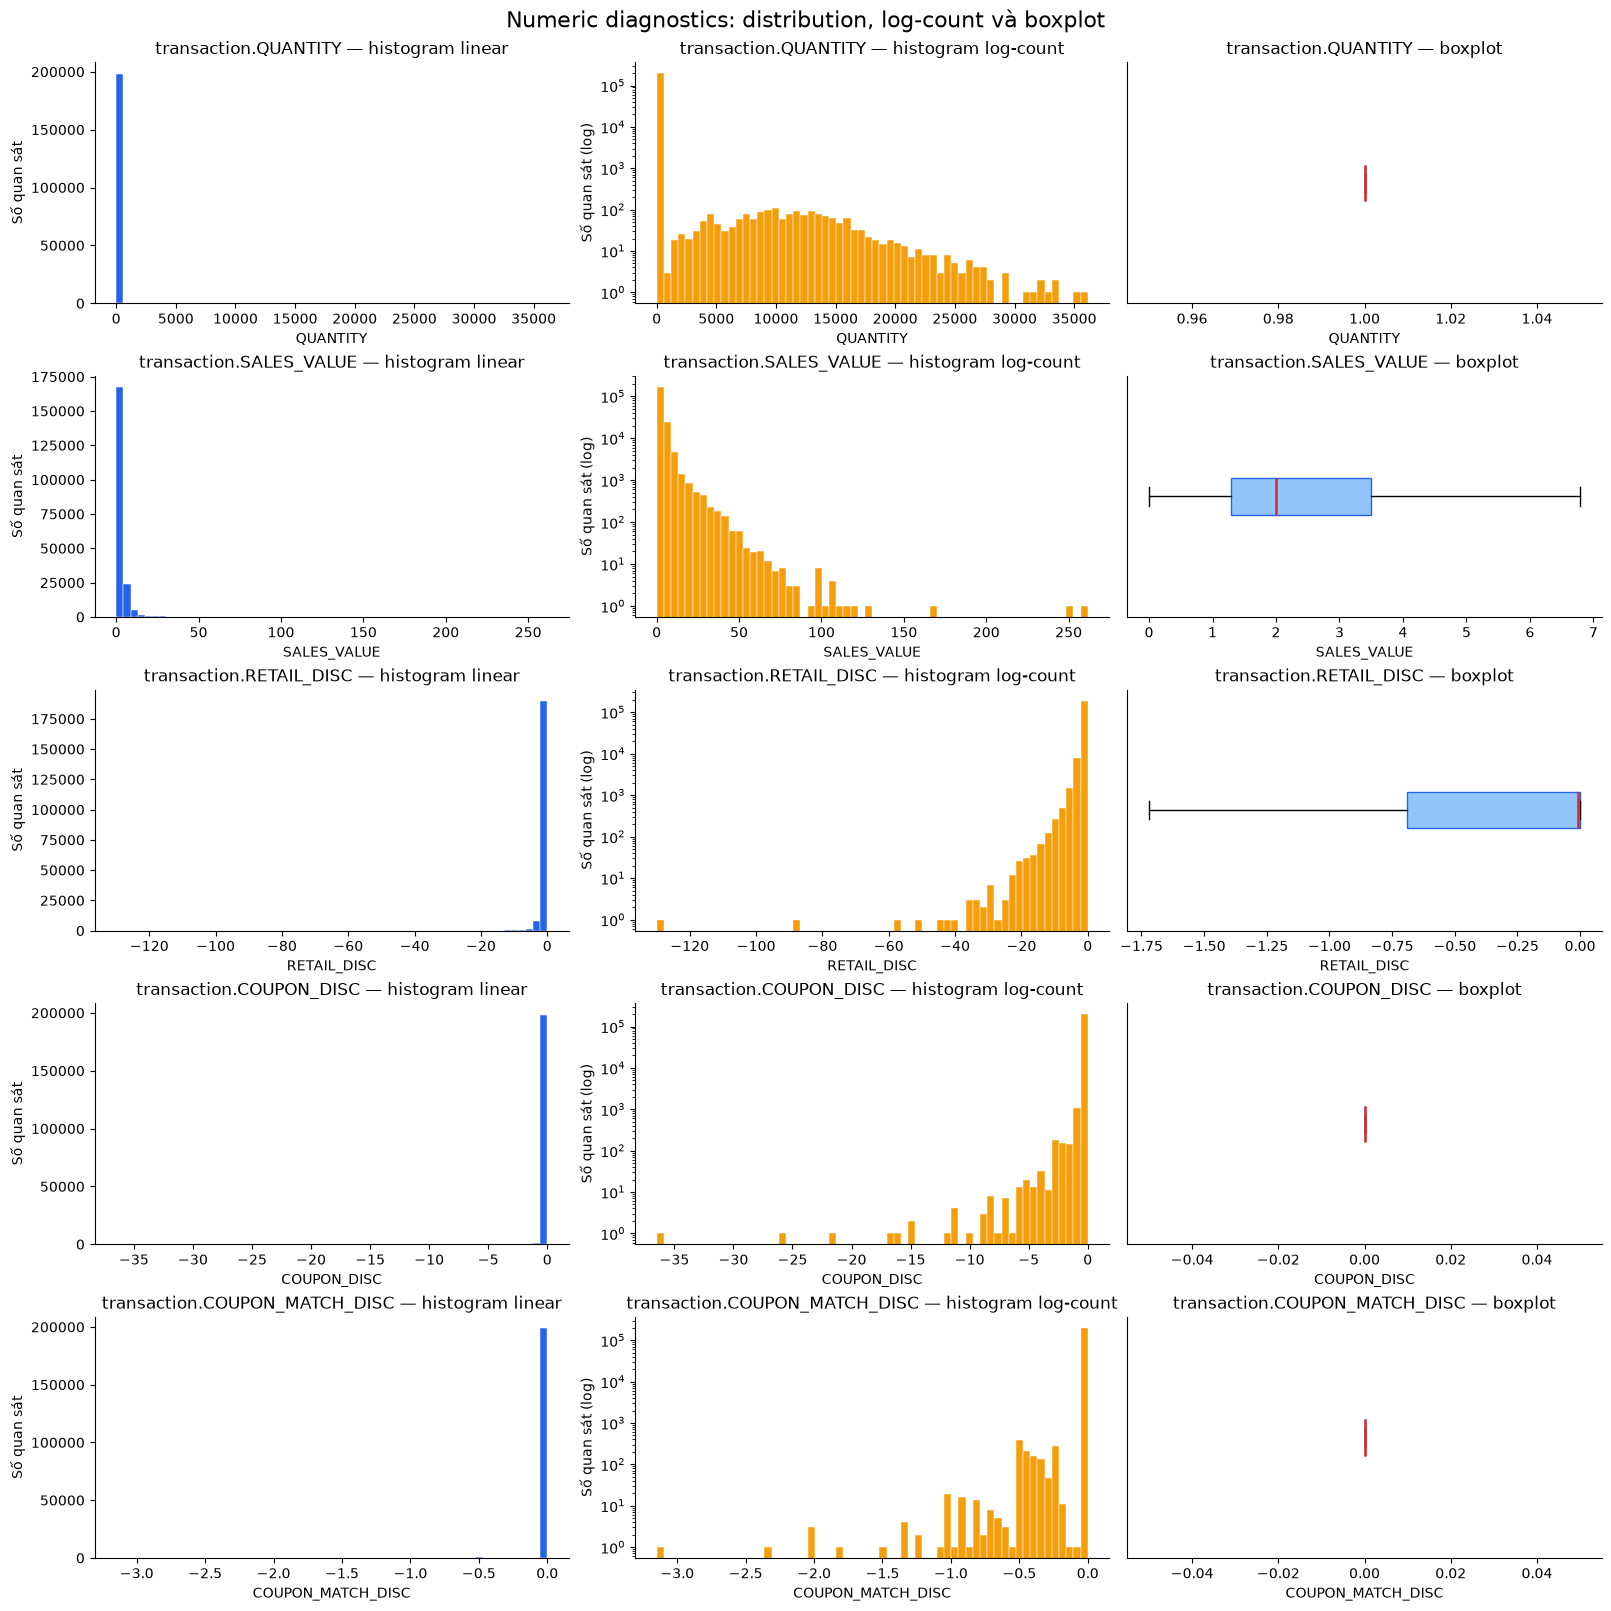

In [53]:
n_numeric_variables = len(numeric_values)
numeric_diagnostics_figure, numeric_diagnostics_axes = plt.subplots(
    n_numeric_variables,
    3,
    figsize=(16, max(4, 3.2 * n_numeric_variables)),
    squeeze=False,
    layout="constrained",
)
for row_index, ((table_name, column), values) in enumerate(numeric_values.items()):
    plot_values = (
        values.sample(NUMERIC_PLOT_SAMPLE_SIZE, random_state=42)
        if len(values) > NUMERIC_PLOT_SAMPLE_SIZE
        else values
    )
    linear_axis, log_axis, box_axis = numeric_diagnostics_axes[row_index]
    linear_axis.hist(
        plot_values, bins=NUMERIC_HISTOGRAM_BINS,
        color="#2563EB", edgecolor="white", linewidth=0.35,
    )
    log_axis.hist(
        plot_values, bins=NUMERIC_HISTOGRAM_BINS,
        color="#F59E0B", edgecolor="white", linewidth=0.35,
    )
    log_axis.set_yscale("log")
    box_axis.boxplot(
        plot_values.to_numpy(),
        vert=False,
        showfliers=False,
        patch_artist=True,
        boxprops={"facecolor": "#93C5FD", "edgecolor": "#2563EB"},
        medianprops={"color": "#DC2626", "linewidth": 1.8},
    )
    linear_axis.set_title(f"{table_name}.{column} — histogram linear")
    log_axis.set_title(f"{table_name}.{column} — histogram log-count")
    box_axis.set_title(f"{table_name}.{column} — boxplot")
    linear_axis.set_ylabel("Số quan sát")
    log_axis.set_ylabel("Số quan sát (log)")
    box_axis.set_yticks([])
    for axis in (linear_axis, log_axis, box_axis):
        axis.set_xlabel(column)
        axis.spines[["top", "right"]].set_visible(False)
numeric_diagnostics_figure.suptitle(
    "Numeric diagnostics: distribution, log-count và boxplot", fontsize=16
)
plt.show()

### 7.2. Kết luận outlier theo từng biến numeric

Outlier được nhận diện bằng ngưỡng `Q1 − 1,5 × IQR` và `Q3 + 1,5 × IQR`. Loại nghi vấn dựa trên phía xuất hiện outlier và skewness. Đây là đề xuất tiền xử lý, không tự động xóa dữ liệu: `loại` chỉ áp dụng cho giá trị không hữu hạn; `cap` dành cho đuôi hiếm và lệch mạnh; `giữ` khi không có outlier hoặc outlier có vẻ là cấu trúc tự nhiên của phân phối.

In [54]:
def summarize_numeric_outliers(table_name, column, values):
    non_finite_mask = values.isin([float("inf"), float("-inf")])
    finite_values = values.loc[~non_finite_mask]
    q1 = float(finite_values.quantile(0.25))
    q3 = float(finite_values.quantile(0.75))
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    low_outlier_mask = values.lt(lower_bound) & ~non_finite_mask
    high_outlier_mask = values.gt(upper_bound) & ~non_finite_mask
    outlier_mask = low_outlier_mask | high_outlier_mask | non_finite_mask
    n_rows = int(values.size)
    n_outliers = int(outlier_mask.sum())
    outlier_pct = n_outliers / n_rows * 100 if n_rows else 0.0
    n_low = int(low_outlier_mask.sum())
    n_high = int(high_outlier_mask.sum())
    skew = float(finite_values.skew())

    if int(non_finite_mask.sum()) > 0:
        suspected_type = "lỗi kỹ thuật: ±inf / không hữu hạn"
        proposed_action = "loại"
        action_reason = "giá trị không hữu hạn không dùng trực tiếp cho mô hình"
    elif n_outliers == 0:
        suspected_type = "không có outlier theo quy tắc IQR"
        proposed_action = "giữ"
        action_reason = "chưa có bằng chứng cần can thiệp"
    else:
        if n_low > 0 and n_high > 0:
            suspected_type = "đuôi dày hai phía / nhiều nhóm hành vi"
        elif n_high > 0:
            suspected_type = "đuôi phải: giá trị lớn hiếm"
        else:
            suspected_type = "đuôi trái: giá trị nhỏ hoặc âm hiếm"

        if outlier_pct <= 10 and abs(skew) >= 1:
            proposed_action = "cap"
            action_reason = "đuôi tương đối hiếm và phân phối lệch mạnh; cap tại p1/p99 trước khi model"
        else:
            proposed_action = "giữ"
            action_reason = "outlier có vẻ mang tính cấu trúc; cân nhắc transform/robust model"

    has_outlier = n_outliers > 0
    conclusion = (
        f"{'Có' if has_outlier else 'Không'} outlier; "
        f"{n_outliers:,}/{n_rows:,} dòng ({outlier_pct:.2f}%); "
        f"nghi là {suspected_type}; đề xuất {proposed_action}: {action_reason}."
    )
    return {
        "table": table_name,
        "column": column,
        "has_outlier": has_outlier,
        "outlier_rows": n_outliers,
        "outlier_pct": outlier_pct,
        "lower_iqr_bound": lower_bound,
        "upper_iqr_bound": upper_bound,
        "suspected_outlier_type": suspected_type,
        "proposed_action": proposed_action,
        "conclusion": conclusion,
    }

numeric_outlier_conclusions = pd.DataFrame([
    summarize_numeric_outliers(table_name, column, values)
    for (table_name, column), values in numeric_values.items()
])
numeric_outlier_conclusions

,table,column,has_outlier,outlier_rows,outlier_pct,lower_iqr_bound,upper_iqr_bound,suspected_outlier_type,proposed_action,conclusion
0,transaction,QUANTITY,True,544765,20.986951,1.000,1.000,đuôi dày hai phía / nhiều nhóm hành vi,giữ,"Có outlier; 544,765/2,595,732 dòng (20.99%); n..."
1,transaction,SALES_VALUE,True,190644,7.344518,-2.010,6.790,đuôi phải: giá trị lớn hiếm,cap,"Có outlier; 190,644/2,595,732 dòng (7.34%); ng..."
2,transaction,RETAIL_DISC,True,206313,7.948163,-1.725,1.035,đuôi dày hai phía / nhiều nhóm hành vi,cap,"Có outlier; 206,313/2,595,732 dòng (7.95%); ng..."
3,transaction,COUPON_DISC,True,36422,1.403149,0.000,0.000,đuôi trái: giá trị nhỏ hoặc âm hiếm,cap,"Có outlier; 36,422/2,595,732 dòng (1.40%); ngh..."
4,transaction,COUPON_MATCH_DISC,True,17449,0.672219,0.000,0.000,đuôi trái: giá trị nhỏ hoặc âm hiếm,cap,"Có outlier; 17,449/2,595,732 dòng (0.67%); ngh..."


#### Kết luận xử lý outlier cho từng cột numeric:
- **`QUANTITY`**: Có outlier; chiếm **20.99%** dòng (544,765 dòng theo quy tắc IQR do Q1=Q3=1); nghi là outlier cấu trúc tự nhiên (gom tại 1) kết hợp đuôi phải cực lớn (xăng, mua sỉ B2B); đề xuất **giữ** (xử lý riêng nhánh sản phẩm xăng và log-transform / binning khi đưa vào mô hình).
- **`SALES_VALUE`**: Có outlier; chiếm **7.34%** dòng (190,644 dòng); nghi là outlier đuôi phải do các giao dịch mua sắm giá trị lớn hiếm; đề xuất **cap** (capping/winsorize tại p99 để tránh kéo lệch gradient/trọng số mô hình).
- **`RETAIL_DISC`**: Có outlier; chiếm **7.95%** dòng (206,313 dòng); nghi là outlier đuôi trái (giảm giá khuyến mại sâu theo đợt) kèm 36 dòng lỗi kỹ thuật mang giá trị dương (>0); đề xuất **cap** (capping đuôi âm tại p1; riêng 36 dòng dương thì loại bỏ hoặc đưa về 0).
- **`COUPON_DISC`**: Có outlier; chiếm **1.40%** dòng (36,422 dòng do phân phối zero-inflated, >98% dòng bằng 0); nghi là outlier đuôi trái (áp mã giảm giá coupon giá trị cao); đề xuất **cap** (capping đuôi âm tại p1 khi dùng làm biến liên tục, hoặc tách cờ nhị phân `has_coupon`).
- **`COUPON_MATCH_DISC`**: Có outlier; chiếm **0.67%** dòng (17,449 dòng do phân phối zero-inflated, >99% dòng bằng 0); nghi là outlier đuôi trái (chính sách match coupon giá trị lớn); đề xuất **cap** (capping đuôi âm tại p1 khi dùng làm biến liên tục, hoặc tách cờ nhị phân).


### 7.3. QUANTITY, fuel và key-frequency diagnostics

Xăng được xác định từ taxonomy sản phẩm (`DEPARTMENT`, `COMMODITY_DESC`, `SUB_COMMODITY_DESC`) bằng các từ khóa gasoline/fuel/diesel/petrol; tuyệt đối không dùng `MANUFACTURER`. Các thống kê và outlier table dùng toàn bộ dữ liệu; biểu đồ có thể dùng mẫu cố định để render ổn định.

In [55]:
FUEL_TAXONOMY_PATTERN = r"\b(?:GASOLINE|MOTOR\s+FUEL|FUEL|DIESEL|PETROL)\b"
product_taxonomy = pd.read_csv(
    raw_dir / "product.csv",
    usecols=[
        "PRODUCT_ID", "MANUFACTURER", "DEPARTMENT",
        "COMMODITY_DESC", "SUB_COMMODITY_DESC",
    ],
)
taxonomy_text = (
    product_taxonomy[["DEPARTMENT", "COMMODITY_DESC", "SUB_COMMODITY_DESC"]]
    .fillna("")
    .astype("string")
    .agg(" | ".join, axis=1)
    .str.upper()
)
product_taxonomy["is_fuel"] = taxonomy_text.str.contains(
    FUEL_TAXONOMY_PATTERN, regex=True, na=False
)
fuel_product_ids = set(
    product_taxonomy.loc[product_taxonomy["is_fuel"], "PRODUCT_ID"]
)
manufacturer_by_product = (
    product_taxonomy
    .drop_duplicates("PRODUCT_ID")
    .set_index("PRODUCT_ID")["MANUFACTURER"]
)

transaction_numeric_columns = list(numeric_columns_by_table.loc["transaction"])
transaction_detail_columns = list(dict.fromkeys([
    "household_key", "BASKET_ID", "DAY", "PRODUCT_ID", "STORE_ID",
    *transaction_numeric_columns,
]))
transaction_detail = pd.read_csv(
    raw_dir / "transaction_data.csv", usecols=transaction_detail_columns
)
transaction_detail["is_fuel"] = transaction_detail["PRODUCT_ID"].isin(
    fuel_product_ids
)
transaction_detail["MANUFACTURER"] = transaction_detail["PRODUCT_ID"].map(
    manufacturer_by_product
)

#### QUANTITY chuyên biệt

`value_counts` giữ bản chất rời rạc của QUANTITY; log-bin chỉ dùng phần đuôi dương; boxplot dùng các dòng không phải xăng. Bảng phân vị đi đến p99.99 cho cả toàn bộ transaction và phần không phải xăng.

In [56]:
quantity_all = pd.to_numeric(transaction_detail["QUANTITY"], errors="coerce").dropna()
quantity_non_fuel = pd.to_numeric(
    transaction_detail.loc[~transaction_detail["is_fuel"], "QUANTITY"],
    errors="coerce",
).dropna()
quantity_value_counts = (
    quantity_all.value_counts()
    .sort_index()
    .rename("n_rows")
    .to_frame()
)
quantity_value_counts["row_pct"] = (
    quantity_value_counts["n_rows"] / len(quantity_all) * 100
)
quantity_value_counts["cumulative_pct"] = quantity_value_counts["row_pct"].cumsum()
quantity_value_counts.index.name = "QUANTITY"

QUANTITY_QUANTILES = {
    "min": 0.0, "p1": 0.01, "p25": 0.25, "median": 0.50,
    "p75": 0.75, "p90": 0.90, "p95": 0.95, "p99": 0.99,
    "p99.9": 0.999, "p99.99": 0.9999, "max": 1.0,
}
quantity_quantiles = pd.DataFrame({
    "all_transaction": pd.Series({
        label: quantity_all.quantile(probability)
        for label, probability in QUANTITY_QUANTILES.items()
    }),
    "non_fuel": pd.Series({
        label: quantity_non_fuel.quantile(probability)
        for label, probability in QUANTITY_QUANTILES.items()
    }),
})
display(quantity_value_counts.head(30), quantity_quantiles)

,n_rows,row_pct,cumulative_pct
QUANTITY,,,
0,14466,0.557299,0.557299
1,2050967,79.013049,79.570349
2,372373,14.345587,93.915936
3,66962,2.579696,96.495632
4,38667,1.489638,97.985270
5,10918,0.420614,98.405883
6,8981,0.345991,98.751874
7,1379,0.053126,98.805000
8,2531,0.097506,98.902506


,all_transaction,non_fuel
min,0.000,0.0
p1,1.000,1.0
p25,1.000,1.0
median,1.000,1.0
p75,1.000,1.0
p90,2.000,2.0
p95,3.000,3.0
p99,10.000,5.0
p99.9,16943.538,10.0
p99.99,25011.000,23.0


C:\Users\manhh\AppData\Local\Temp\ipykernel_21760\216175233.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  quantity_axes[2].boxplot(


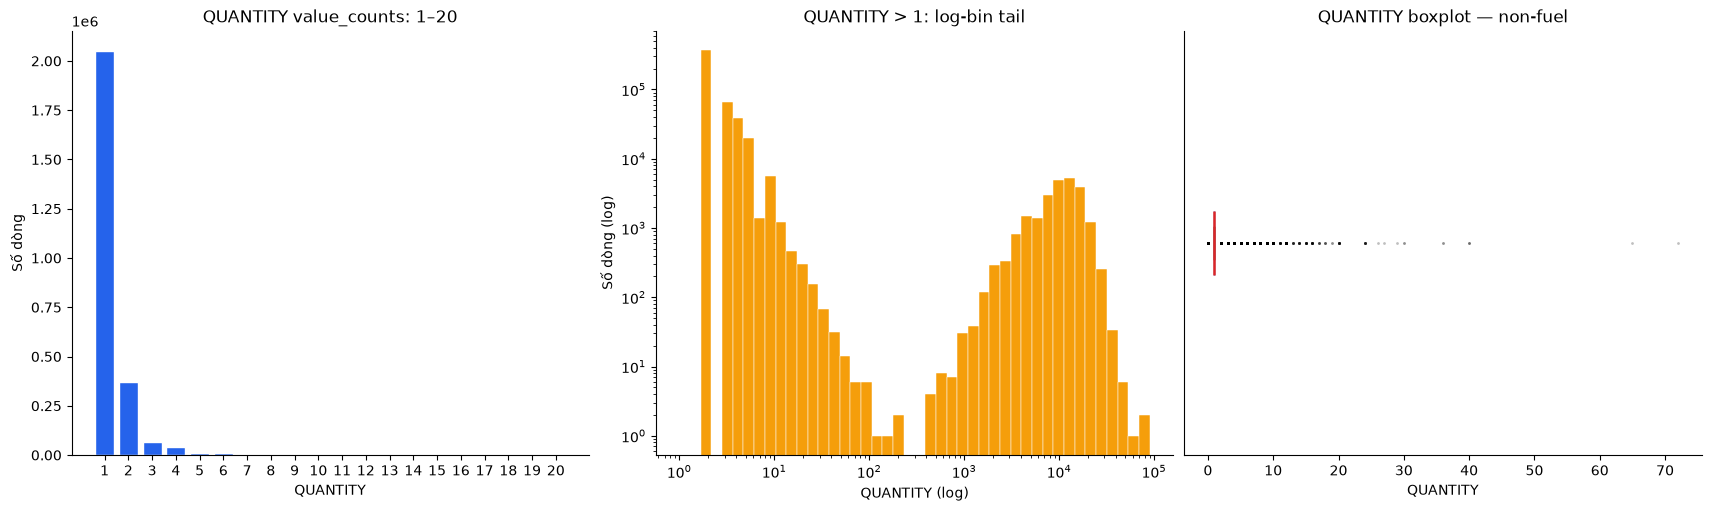

In [57]:
quantity_figure, quantity_axes = plt.subplots(
    1, 3, figsize=(17, 5), layout="constrained"
)
quantity_discrete = (
    quantity_all.loc[quantity_all.ge(1) & quantity_all.mod(1).eq(0)]
    .astype("int64")
    .value_counts()
    .reindex(range(1, 21), fill_value=0)
)
quantity_axes[0].bar(
    quantity_discrete.index, quantity_discrete.values,
    color="#2563EB", edgecolor="white",
)
quantity_axes[0].set_xticks(range(1, 21))
quantity_axes[0].set(
    title="QUANTITY value_counts: 1–20",
    xlabel="QUANTITY", ylabel="Số dòng",
)

quantity_positive_tail = quantity_all.loc[quantity_all.gt(1)]
quantity_tail_max = max(2.0, float(quantity_positive_tail.max()))
quantity_log_bins = np.unique(np.geomspace(1, quantity_tail_max, 45))
quantity_axes[1].hist(
    quantity_positive_tail, bins=quantity_log_bins,
    color="#F59E0B", edgecolor="white", linewidth=0.35,
)
quantity_axes[1].set_xscale("log")
quantity_axes[1].set_yscale("log")
quantity_axes[1].set(
    title="QUANTITY > 1: log-bin tail",
    xlabel="QUANTITY (log)", ylabel="Số dòng (log)",
)

quantity_non_fuel_plot = (
    quantity_non_fuel.sample(NUMERIC_PLOT_SAMPLE_SIZE, random_state=42)
    if len(quantity_non_fuel) > NUMERIC_PLOT_SAMPLE_SIZE
    else quantity_non_fuel
)
quantity_axes[2].boxplot(
    quantity_non_fuel_plot.to_numpy(),
    vert=False, showfliers=True, patch_artist=True,
    flierprops={"marker": ".", "markersize": 2, "alpha": 0.25},
    boxprops={"facecolor": "#93C5FD", "edgecolor": "#2563EB"},
    medianprops={"color": "#DC2626", "linewidth": 1.8},
)
quantity_axes[2].set(
    title="QUANTITY boxplot — non-fuel", xlabel="QUANTITY",
)
quantity_axes[2].set_yticks([])
for axis in quantity_axes:
    axis.spines[["top", "right"]].set_visible(False)
plt.show()

**Kết luận QUANTITY:** QUANTITY ≈ 1 ở gần như mọi dòng và `IQR = 0`. Vì vậy boxplot/IQR gắn cờ mọi giá trị khác 1 như outlier thống kê; không được đồng nhất điều này với lỗi dữ liệu. Phải tách giao dịch xăng và kiểm tra nghiệp vụ trước khi cap hoặc loại.

#### Kiểm tra xăng: SALES_VALUE và giá trên đơn vị

In [60]:
fuel_lines = transaction_detail.loc[transaction_detail["is_fuel"]].copy()
fuel_lines["unit_price"] = (
    pd.to_numeric(fuel_lines["SALES_VALUE"], errors="coerce")
    / pd.to_numeric(fuel_lines["QUANTITY"], errors="coerce").replace(0, np.nan)
)
fuel_coverage = pd.Series({
    "n_fuel_products": len(fuel_product_ids),
    "n_fuel_lines": len(fuel_lines),
    "n_fuel_baskets": fuel_lines["BASKET_ID"].nunique(),
    "n_fuel_households": fuel_lines["household_key"].nunique(),
    "fuel_line_pct": len(fuel_lines) / len(transaction_detail) * 100,
}, name="value").to_frame()
fuel_value_summary = pd.DataFrame({
    "SALES_VALUE": pd.to_numeric(fuel_lines["SALES_VALUE"], errors="coerce"),
    "price_per_unit": fuel_lines["unit_price"],
}).describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]).T
display(fuel_coverage, fuel_value_summary)

,value
n_fuel_products,35.000000
n_fuel_lines,24962.000000
n_fuel_baskets,24952.000000
n_fuel_households,1438.000000
fuel_line_pct,0.961656


,count,mean,std,min,1%,25%,50%,75%,99%,max
SALES_VALUE,24962.0,25.396894,12.711598,0.030000,4.532200,16.140000,24.115000,32.870000,61.1039,250.0
price_per_unit,24962.0,1.189633,4.962020,0.001659,0.001839,0.002108,0.002309,0.002699,25.0000,100.0


### Cần kiểm tra?
- sao số lượng xăng lớn mà unit price lên đến tận 100, trong khi max có 250???

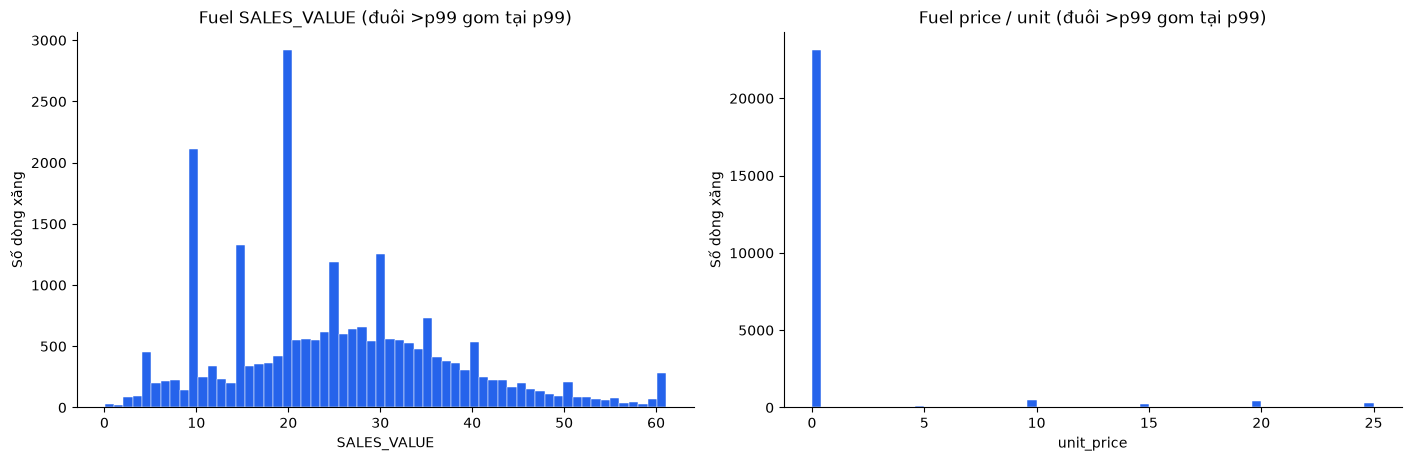

In [61]:
fuel_value_figure, fuel_value_axes = plt.subplots(
    1, 2, figsize=(14, 4.5), layout="constrained"
)
for axis, column, title in (
    (fuel_value_axes[0], "SALES_VALUE", "Fuel SALES_VALUE"),
    (fuel_value_axes[1], "unit_price", "Fuel price / unit"),
):
    values = pd.to_numeric(fuel_lines[column], errors="coerce").dropna()
    plot_limit = float(values.quantile(0.99))
    axis.hist(
        values.clip(upper=plot_limit), bins=60,
        color="#2563EB", edgecolor="white", linewidth=0.35,
    )
    axis.set(
        title=f"{title} (đuôi >p99 gom tại p99)",
        xlabel=column, ylabel="Số dòng xăng",
    )
    axis.spines[["top", "right"]].set_visible(False)
plt.show()

#### Outlier transaction sau khi loại phần xăng khỏi phép đánh giá

In [62]:
non_fuel_numeric_outlier_conclusions = pd.DataFrame([
    summarize_numeric_outliers(
        "transaction_non_fuel",
        column,
        pd.to_numeric(
            transaction_detail.loc[~transaction_detail["is_fuel"], column],
            errors="coerce",
        ).dropna().astype("float64"),
    )
    for column in transaction_numeric_columns
])
non_fuel_numeric_outlier_conclusions

,table,column,has_outlier,outlier_rows,outlier_pct,lower_iqr_bound,upper_iqr_bound,suspected_outlier_type,proposed_action,conclusion
0,transaction_non_fuel,QUANTITY,True,521612,20.290108,1.000,1.000,đuôi dày hai phía / nhiều nhóm hành vi,giữ,"Có outlier; 521,612/2,570,770 dòng (20.29%); n..."
1,transaction_non_fuel,SALES_VALUE,True,173792,6.760309,-1.935,6.585,đuôi phải: giá trị lớn hiếm,cap,"Có outlier; 173,792/2,570,770 dòng (6.76%); ng..."
2,transaction_non_fuel,RETAIL_DISC,True,213219,8.293974,-1.650,0.990,đuôi dày hai phía / nhiều nhóm hành vi,cap,"Có outlier; 213,219/2,570,770 dòng (8.29%); ng..."
3,transaction_non_fuel,COUPON_DISC,True,36422,1.416774,0.000,0.000,đuôi trái: giá trị nhỏ hoặc âm hiếm,cap,"Có outlier; 36,422/2,570,770 dòng (1.42%); ngh..."
4,transaction_non_fuel,COUPON_MATCH_DISC,True,17449,0.678746,0.000,0.000,đuôi trái: giá trị nhỏ hoặc âm hiếm,cap,"Có outlier; 17,449/2,570,770 dòng (0.68%); ngh..."


In [ ]:
CATEGORY_COLUMNS = ["DEPARTMENT", "COMMODITY_DESC", "SUB_COMMODITY_DESC"]
category_lookup = product_taxonomy.drop_duplicates("PRODUCT_ID").set_index("PRODUCT_ID")
for category_column in CATEGORY_COLUMNS:
    transaction_detail[category_column] = (
        transaction_detail["PRODUCT_ID"]
        .map(category_lookup[category_column])
        .fillna("<MISSING>")
        .astype("category")
    )


### 7.6. Taxonomy của top 0,01% QUANTITY

Các dòng có `QUANTITY ≥ p99.99` được gom theo `DEPARTMENT × COMMODITY_DESC`. Ngưỡng giữ toàn bộ ties nên số dòng có thể lớn hơn đúng 0,01%. Cột `fuel_line_pct` dùng cờ xăng xác định từ taxonomy; `MANUFACTURER` không tham gia phép xác định.

In [65]:
quantity_numeric = pd.to_numeric(transaction_detail["QUANTITY"], errors="coerce")
quantity_p9999 = float(quantity_numeric.quantile(0.9999))
largest_quantity_lines = transaction_detail.loc[
    quantity_numeric.ge(quantity_p9999),
    [
        "PRODUCT_ID", "BASKET_ID", "household_key", "QUANTITY",
        "SALES_VALUE", "DEPARTMENT", "COMMODITY_DESC",
        "SUB_COMMODITY_DESC", "is_fuel",
    ],
].copy()
largest_quantity_taxonomy = (
    largest_quantity_lines
    .groupby(["DEPARTMENT", "COMMODITY_DESC"], observed=True, dropna=False)
    .agg(
        n_lines=("PRODUCT_ID", "size"),
        n_products=("PRODUCT_ID", "nunique"),
        n_baskets=("BASKET_ID", "nunique"),
        n_households=("household_key", "nunique"),
        min_quantity=("QUANTITY", "min"),
        median_quantity=("QUANTITY", "median"),
        max_quantity=("QUANTITY", "max"),
        median_sales_value=("SALES_VALUE", "median"),
        fuel_lines=("is_fuel", "sum"),
    )
    .reset_index()
)
largest_quantity_taxonomy["line_pct_within_top_0_01pct"] = (
    largest_quantity_taxonomy["n_lines"] / len(largest_quantity_lines) * 100
)
largest_quantity_taxonomy["fuel_line_pct"] = (
    largest_quantity_taxonomy["fuel_lines"]
    / largest_quantity_taxonomy["n_lines"] * 100
)
largest_quantity_taxonomy = largest_quantity_taxonomy.sort_values(
    ["n_lines", "max_quantity"], ascending=[False, False]
)
largest_quantity_overview = pd.Series({
    "p99.99_quantity_threshold": quantity_p9999,
    "n_lines_at_or_above_threshold": len(largest_quantity_lines),
    "actual_line_pct": len(largest_quantity_lines) / quantity_numeric.notna().sum() * 100,
    "fuel_line_pct": largest_quantity_lines["is_fuel"].mean() * 100,
}, name="value").to_frame()
display(largest_quantity_overview, largest_quantity_taxonomy)

,value
p99.99_quantity_threshold,25011.000000
n_lines_at_or_above_threshold,261.000000
actual_line_pct,0.010055
fuel_line_pct,100.000000


,DEPARTMENT,COMMODITY_DESC,n_lines,n_products,n_baskets,n_households,min_quantity,median_quantity,max_quantity,median_sales_value,fuel_lines,line_pct_within_top_0_01pct,fuel_line_pct
0,KIOSK-GAS,COUPON/MISC ITEMS,204,4,204,66,25011,27580.0,89638,63.93,204,78.160920,100.0
2,MISC SALES TRAN,COUPON/MISC ITEMS,56,4,56,21,25012,27597.5,85055,75.00,56,21.455939,100.0
1,KIOSK-GAS,FUEL,1,1,1,1,30080,30080.0,30080,86.01,1,0.383142,100.0


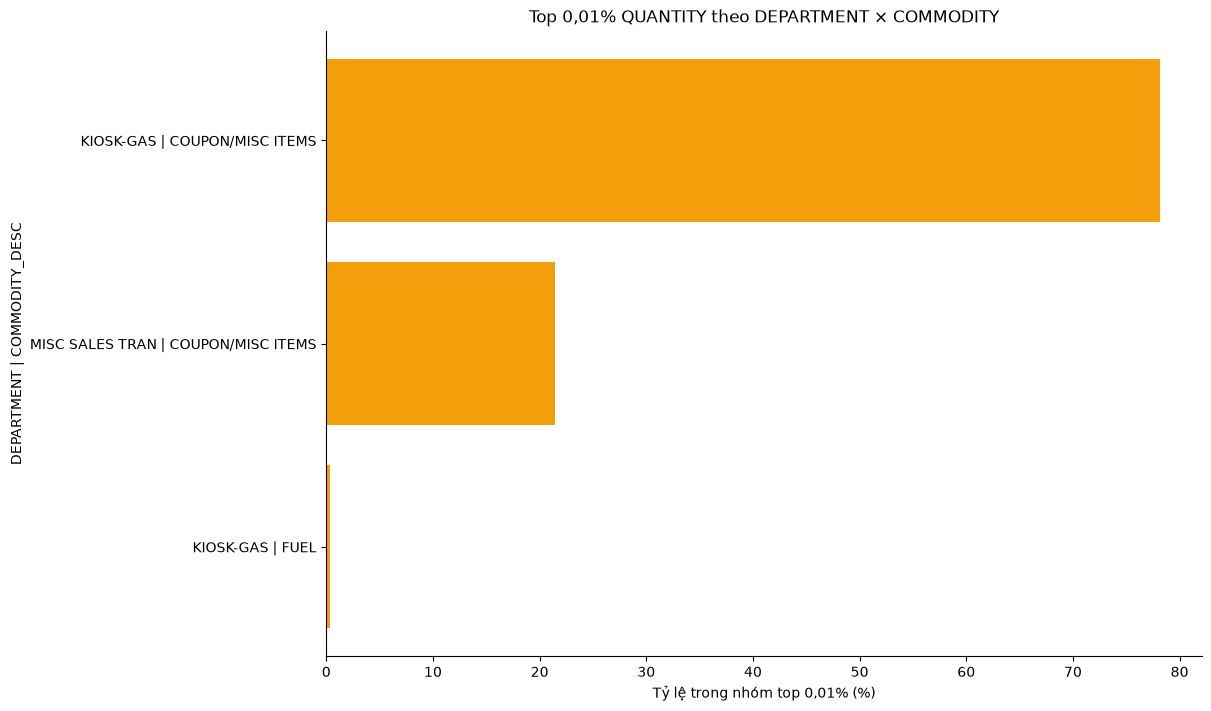

In [66]:
largest_quantity_top = largest_quantity_taxonomy.head(20).sort_values("n_lines")
largest_quantity_labels = (
    largest_quantity_top["DEPARTMENT"].astype("string")
    + " | "
    + largest_quantity_top["COMMODITY_DESC"].astype("string")
)
largest_quantity_figure, largest_quantity_axis = plt.subplots(
    figsize=(12, 7), layout="constrained"
)
largest_quantity_axis.barh(
    largest_quantity_labels,
    largest_quantity_top["line_pct_within_top_0_01pct"],
    color=[
        "#F59E0B" if value > 0 else "#2563EB"
        for value in largest_quantity_top["fuel_lines"]
    ],
)
largest_quantity_axis.set(
    title="Top 0,01% QUANTITY theo DEPARTMENT × COMMODITY",
    xlabel="Tỷ lệ trong nhóm top 0,01% (%)",
    ylabel="DEPARTMENT | COMMODITY_DESC",
)
largest_quantity_axis.spines[["top", "right"]].set_visible(False)
plt.show()